# 02 Bunches and answer sheet

**Goal:** use the event timeline from notebook 01 to answer three questions:
1. **When** did things go wrong? Find the **bunches**: dates where one defect clumps together.
2. **What happened around each bunch?** Collect the alarms, maintenance and nozzle hours just before and during it.
3. **Why?** You write the cause and fix for each bunch. The result is the **answer sheet**.

**Why this matters later:** the answer sheet is the marking scheme. At the end you ask your knowledge graph + LLM system
"why did this job go wrong?" for every bad job, and compare its answer with this sheet.

**Input:** `data/processed/event_timeline.csv` (from notebook 01).
**Output:** `data/processed/answer_sheet.csv` (one row per bunch) and `data/processed/answer_key_jobs.csv` (one row per bad job).

Run one block at a time with **Shift + Enter**.

## 0. Load the timeline
**Watch out:** if you open the CSV in Excel and press Save, Excel rewrites the dates as `1/9/2026 6:04` (day first, seconds lost).
Notebook 01 writes ISO dates (`2026-09-01 06:04:00`), so we read them with `format="ISO8601"`. If Excel has re-saved the file, this line stops with an error: re-run notebook 01 instead of fixing the dates by hand. (Don't use `dayfirst=True, format="mixed"`: it silently swaps day and month in ISO dates.)

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

OUT = Path("..") / "data" / "processed"
tl = pd.read_csv(OUT / "event_timeline.csv")
tl["time"] = pd.to_datetime(tl["time"], format="ISO8601")
print(len(tl), "events from", tl["time"].min(), "to", tl["time"].max())
tl["event_type"].value_counts()

1204 events from 2026-09-01 06:04:00 to 2026-10-10 00:22:00


event_type
job_start             527
inspection            416
alarm                 217
maintenance_glass      28
maintenance_nozzle      8
maintenance_other       8
Name: count, dtype: int64

## 1. One row per job
The timeline has a `job_start` row and (for most jobs) an `inspection` row with the same `job_id`. We join them so each job has its **start time** and its **defect**.

**Decision (from notebook 01):** we group by the **job date**, not the inspection date, because that is when the defect was made.
Jobs that were never inspected get `not_inspected` and are left out of the percentages.

In [2]:
starts = tl[tl["event_type"] == "job_start"][["job_id", "time", "detail"]].rename(columns={"time": "job_time"})
insp = tl[tl["event_type"] == "inspection"][["job_id", "detail"]].copy()
insp["defect"] = insp["detail"].str.split(" | ", regex=False).str[1]     # "NOK | dross" -> "dross"

jobs = starts.merge(insp[["job_id", "defect"]], on="job_id", how="left")
jobs["defect"] = jobs["defect"].fillna("not_inspected")
jobs["date"] = jobs["job_time"].dt.normalize()
jobs["nozzle_h"] = jobs["detail"].str.extract(r"nozzle ([\d.]+) h")[0].astype(float)
jobs["shift"] = jobs["job_time"].dt.hour.map(lambda h: "early" if h < 14 else "late")

print(len(jobs), "jobs")
jobs["defect"].value_counts()

527 jobs


defect
ok                 250
not_inspected      111
dross               51
incomplete_cut      51
rough_cut           37
unknown             14
bevel_deviation     12
burnt_edge           1
Name: count, dtype: int64

## 2. Daily defect table
This is your Excel trend sheet: for each day, how many inspected jobs had each defect.
Read down one column and you can already see the clumps.

In [3]:
inspected = jobs[jobs["defect"] != "not_inspected"]
daily = pd.crosstab(inspected["date"], inspected["defect"])
daily["inspected"] = daily.sum(axis=1)
daily["ok_rate"] = (daily["ok"] / daily["inspected"]).round(2)
daily

defect,bevel_deviation,burnt_edge,dross,incomplete_cut,ok,rough_cut,unknown,inspected,ok_rate
date,,,,,,,,,
2026-09-01,0,0,0,0,9,1,0,10,0.90
2026-09-02,0,0,1,0,7,1,0,9,0.78
2026-09-03,0,1,1,1,8,1,1,13,0.62
2026-09-04,0,0,0,2,8,0,0,10,0.80
2026-09-05,0,0,1,2,9,0,1,13,0.69
2026-09-07,0,0,2,0,8,0,0,10,0.80
2026-09-08,0,0,1,0,6,0,1,8,0.75
2026-09-09,0,0,0,7,7,0,0,14,0.50
2026-09-10,0,0,1,0,6,4,0,11,0.55


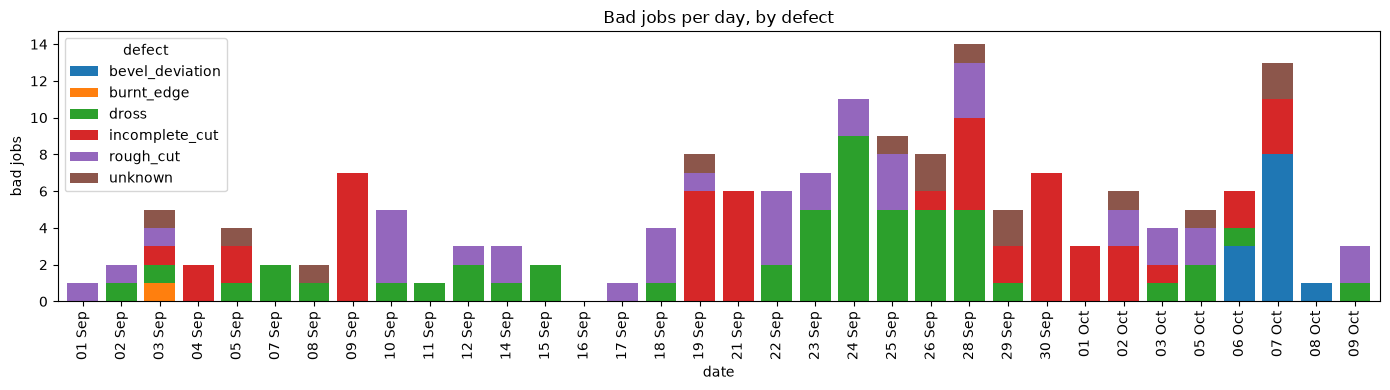

In [4]:
defect_cols = [c for c in daily.columns if c not in ("ok", "inspected", "ok_rate")]
ax = daily[defect_cols].plot(kind="bar", stacked=True, figsize=(14, 4), width=0.8)
ax.set_xticklabels([d.strftime("%d %b") for d in daily.index], rotation=90)
ax.set_ylabel("bad jobs")
ax.set_title("Bad jobs per day, by defect")
plt.tight_layout()
plt.show()

## 3. Find the bunches automatically
In Excel you picked the bunches by eye. Here we write the rule down, so anyone gets the same answer:

- A day is **bad for a defect** if that defect appears on at least `MIN_JOBS` jobs **and** at least `MIN_SHARE` of the inspected jobs that day.
- Bad days for the **same defect** that are at most `MAX_GAP_DAYS` apart join into one **bunch** (so a Sunday off doesn't split a bunch).

**These three numbers are decisions.** Try changing them and see how the bunches change. Write the values you choose in your report.

In [5]:
MIN_JOBS = 3        # at least 3 jobs with this defect on the day
MIN_SHARE = 0.25    # and at least 25% of that day's inspected jobs
MAX_GAP_DAYS = 2    # bad days up to 2 days apart belong to the same bunch

rows = []
for d in [c for c in defect_cols if c != "unknown"]:
    is_bad = (daily[d] >= MIN_JOBS) & (daily[d] / daily["inspected"] >= MIN_SHARE)
    for day in daily.index[is_bad]:
        rows.append({"defect": d, "date": day})
bad_days = pd.DataFrame(rows).sort_values(["defect", "date"])

# a new bunch starts when the defect changes or the gap to the previous bad day is too big
gap = bad_days.groupby("defect")["date"].diff().dt.days
bad_days["bunch_no"] = (gap.isna() | (gap > MAX_GAP_DAYS)).cumsum()

bunches = (bad_days.groupby("bunch_no")
                   .agg(defect=("defect", "first"), start=("date", "min"), end=("date", "max"), bad_days=("date", "count"))
                   .sort_values("start").reset_index(drop=True))
bunches.insert(0, "bunch_id", [f"B{i + 1}" for i in range(len(bunches))])

def bad_jobs_in(b):
    return jobs[(jobs["defect"] == b["defect"]) & (jobs["date"] >= b["start"]) & (jobs["date"] <= b["end"])]

bunches["n_bad_jobs"] = bunches.apply(lambda b: len(bad_jobs_in(b)), axis=1)
bunches

,bunch_id,defect,start,end,bad_days,n_bad_jobs
0,B1,incomplete_cut,2026-09-09,2026-09-09,1,7
1,B2,rough_cut,2026-09-10,2026-09-10,1,4
2,B3,incomplete_cut,2026-09-19,2026-09-21,2,12
3,B4,rough_cut,2026-09-22,2026-09-22,1,4
4,B5,dross,2026-09-23,2026-09-28,5,29
5,B6,rough_cut,2026-09-25,2026-09-25,1,3
6,B7,incomplete_cut,2026-09-28,2026-10-02,3,20
7,B8,bevel_deviation,2026-10-06,2026-10-07,2,11


**Check against your Excel work:** do these match your bunches? If one is missing or extra, is it the rule or your eye that's wrong?
Small clumps (like 4 to 5 Sep with 2 incomplete cuts a day) fall below the rule. That's fine, as long as you say so.

## 4. Evidence for each bunch
For each bunch, look at a window from `LOOK_BACK` days **before** it starts until it ends. Causes come *before* effects.

Three kinds of evidence:
- **Alarms:** how many of each code, compared with **normal**. Code 2105 appears almost every day, so 16 of them means nothing on its own. What matters is *more than usual*.
- **Maintenance:** what was done, and what was **not** done (for example, no glass cleaning for several days).
- **Nozzle hours:** how worn the nozzle was during the bunch.

In [6]:
LOOK_BACK = pd.Timedelta(days=3)

alarms = tl[tl["event_type"] == "alarm"].copy()
alarms["code"] = alarms["detail"].str.split(" ").str[0]
maint = tl[tl["event_type"].str.startswith("maintenance")]

n_days = (tl["time"].max() - tl["time"].min()).days + 1
normal_per_day = alarms["code"].value_counts() / n_days      # average alarms per day over the whole period

def evidence(b):
    w_start, w_end = b["start"] - LOOK_BACK, b["end"] + pd.Timedelta(days=1)
    days = (w_end - w_start).days
    a = alarms[(alarms["time"] >= w_start) & (alarms["time"] < w_end)]
    per_day = a["code"].value_counts() / days
    ratio = (per_day / normal_per_day[per_day.index]).round(1)
    unusual = ratio[ratio >= 1.5].sort_values(ascending=False)      # at least 1.5x the normal rate
    m = maint[(maint["time"] >= w_start) & (maint["time"] < w_end)]
    return {
        "unusual_alarms": ", ".join(f"{code} ({x}x normal)" for code, x in unusual.items()) or "none",
        "glass_cleanings": int((m["event_type"] == "maintenance_glass").sum()),
        "window_days": days,
        "nozzle_h_max": bad_jobs_in(b)["nozzle_h"].max(),
        "maintenance_notes": " / ".join(m.loc[m["event_type"] != "maintenance_glass", "detail"]),
    }

ev = bunches.join(bunches.apply(evidence, axis=1, result_type="expand"))
pd.set_option("display.max_colwidth", 200)
ev

,bunch_id,defect,start,end,bad_days,n_bad_jobs,unusual_alarms,glass_cleanings,window_days,nozzle_h_max,maintenance_notes
0,B1,incomplete_cut,2026-09-09,2026-09-09,1,7,none,2,4,24.5,"nozzle changed, routine (time estimated)"
1,B2,rough_cut,2026-09-10,2026-09-10,1,4,none,3,4,40.1,"nozzle changed, routine (time estimated)"
2,B3,incomplete_cut,2026-09-19,2026-09-21,2,12,"6002 (1.9x normal), 4001 (1.7x normal)",4,6,75.3,"12mm mild steel edges rough, using fast program to keep up with order (time estimated)"
3,B4,rough_cut,2026-09-22,2026-09-22,1,4,"4001 (2.5x normal), 1201 (2.4x normal)",2,4,96.2,"nozzle check - looks ok, no change (no spare 2.3) / N2 pressure alarms since morning, informed facilities"
4,B5,dross,2026-09-23,2026-09-28,5,29,1201 (4.3x normal),6,9,159.5,"nozzle check - looks ok, no change (no spare 2.3) / N2 pressure alarms since morning, informed facilities / facilities replaced N2 pressure regulator at tank, pressure ok again / lots of dross on ..."
5,B6,rough_cut,2026-09-25,2026-09-25,1,3,1201 (9.8x normal),5,4,138.6,"nozzle check - looks ok, no change (no spare 2.3) / N2 pressure alarms since morning, informed facilities / facilities replaced N2 pressure regulator at tank, pressure ok again"
6,B7,incomplete_cut,2026-09-28,2026-10-02,3,20,"2105 (2.1x normal), 4001 (1.9x normal)",2,8,167.5,"lots of dross on stainless today, increased gas pressure by 1 bar on some jobs / nozzle changed - old one worn out, orifice not round anymore"
7,B8,bevel_deviation,2026-10-06,2026-10-07,2,11,"3302 (7.8x normal), 3301 (7.8x normal)",1,5,22.8,"lubrication done, chiller filter cleaned / head crash on tipped part, program stopped. checked head, nozzle bent / nozzle replaced after collision (bent) / new nozzle, centred beam, restarted prod..."


To read one bunch in full, print its window from the timeline (job starts hidden to keep it short). Change `"B5"` to any bunch.

In [7]:
b = bunches.set_index("bunch_id").loc["B5"]
window = tl[(tl["time"] >= b["start"] - LOOK_BACK) & (tl["time"] < b["end"] + pd.Timedelta(days=1))]
window[~window["event_type"].isin(["job_start", "inspection"])]

,time,event_type,source,job_id,detail
570,2026-09-21 07:56:11,alarm,alarm_log,JOB-00269,4001 WARNING | Laser power reduced - beam path monitoring
576,2026-09-21 11:02:33,alarm,alarm_log,JOB-00272,4001 WARNING | Laser power reduced - beam path monitoring
578,2026-09-21 11:31:20,alarm,alarm_log,JOB-00273,2105 WARNING | Protective glass contamination - check and clean
579,2026-09-21 11:36:06,alarm,alarm_log,JOB-00273,4001 WARNING | Laser power reduced - beam path monitoring
582,2026-09-21 12:51:28,alarm,alarm_log,JOB-00274,2105 WARNING | Protective glass contamination - check and clean
...,...,...,...,...,...
818,2026-09-28 18:14:03,alarm,alarm_log,JOB-00371,2105 WARNING | Protective glass contamination - check and clean
821,2026-09-28 19:12:41,alarm,alarm_log,JOB-00372,2105 WARNING | Protective glass contamination - check and clean
823,2026-09-28 20:03:33,alarm,alarm_log,JOB-00373,2105 WARNING | Protective glass contamination - check and clean
827,2026-09-28 21:14:41,alarm,alarm_log,JOB-00374,2105 WARNING | Protective glass contamination - check and clean


### See a bunch as one picture: the evidence timeline
Reading tables is slow. This chart puts all five sources on **one shared date axis**, one lane each, so you can read straight down a day:
1. **Inspected jobs**: one dot per job, one row per defect. A cluster of one colour in the shaded strip is the bunch.
2. **Machine alarms**: one tick per warning. Look for a row that gets crowded *just before* the strip.
3. **Maintenance book**: a gap in glass entries means nobody cleaned the glass. A repair where the dots stop is the strongest evidence.
4. **Nozzle hours**: far above the green 40-60 h band means a worn nozzle. A drop to zero is a nozzle change.
5. **Feed vs cutting table**: 100% is the table's speed. Orange dots are `_FAST` programs.

Change `"B7"` to any bunch. The last cell saves one figure per bunch for the report.

In [ ]:
import matplotlib.dates as mdates
import numpy as np

DATA = Path("..") / "datasets"
log = pd.read_csv(DATA / "machine" / "job_log.csv", sep=";", decimal=",").drop_duplicates("JobID")
table = pd.read_csv(DATA / "documents" / "cutting_table.csv")
feed = log.merge(table, left_on=["Material", "Thickness_mm"], right_on=["material", "thickness_mm"])
feed_pct = (feed["FeedRate_mm_min"] / feed["feed_rate_mm_min"] * 100).set_axis(feed["JobID"])   # 100 = cutting-table speed

ALARM_ROWS = {"2105": "2105 glass dirty", "4001": "4001 power reduced", "1201": "1201 gas low",
              "3301": "3301 collision", "3302": "3302 height sensor", "6002": "6002 sheet tip-up"}
MAINT_ROWS = {"maintenance_glass": "glass", "maintenance_nozzle": "nozzle", "maintenance_other": "other"}
DEFECT_COLOURS = {"ok": "lightgrey", "dross": "firebrick", "incomplete_cut": "rebeccapurple", "rough_cut": "darkorange",
                  "bevel_deviation": "teal", "burnt_edge": "goldenrod", "unknown": "khaki", "not_inspected": "white"}

def plot_bunch(bunch_id, days_before=4, days_after=3):
    b = bunches.set_index("bunch_id").loc[bunch_id]
    t0, t1 = b["start"] - pd.Timedelta(days=days_before), b["end"] + pd.Timedelta(days=days_after)
    j = jobs[(jobs["job_time"] >= t0) & (jobs["job_time"] < t1)].sort_values("job_time")
    a = alarms[(alarms["time"] >= t0) & (alarms["time"] < t1)]
    m = maint[(maint["time"] >= t0) & (maint["time"] < t1)]

    fig, ax = plt.subplots(5, 1, figsize=(14, 12), sharex=True, gridspec_kw={"height_ratios": [2.2, 2, 1, 1.5, 1.5]})

    # 1. one row per defect, with a little vertical jitter, so dots don't hide each other
    rows = [d for d in DEFECT_COLOURS if d in set(j["defect"])]
    jitter = np.random.default_rng(0).uniform(-0.25, 0.25, len(j))
    for k, d in enumerate(rows):
        pick = (j["defect"] == d).values
        ax[0].scatter(j["job_time"][pick], k + jitter[pick], s=35, c=DEFECT_COLOURS[d], edgecolors="dimgrey", linewidths=0.5)
    ax[0].set_yticks(range(len(rows)), rows)
    ax[0].set_ylim(-0.6, len(rows) - 0.4)
    ax[0].set_title("Inspected jobs: one dot per job, one row per defect", loc="left")

    # 2. alarms: one tick per warning, one row per code
    for k, code in enumerate(ALARM_ROWS):
        ax[1].vlines(a.loc[a["code"] == code, "time"], k - 0.35, k + 0.35, colors="steelblue")
    ax[1].set_yticks(range(len(ALARM_ROWS)), ALARM_ROWS.values())
    ax[1].set_title("Machine alarms: one tick per warning", loc="left")

    # 3. maintenance book
    for k, etype in enumerate(MAINT_ROWS):
        x = m.loc[m["event_type"] == etype, "time"]
        ax[2].scatter(x, [k] * len(x), marker="D", s=45, c="seagreen")
    ax[2].set_yticks(range(len(MAINT_ROWS)), MAINT_ROWS.values())
    ax[2].set_ylim(-0.6, len(MAINT_ROWS) - 0.4)
    ax[2].set_title("Maintenance book: one diamond per entry", loc="left")

    # 4. nozzle wear
    ax[3].axhspan(40, 60, color="seagreen", alpha=0.15, label="guide: replace at 40-60 h")
    ax[3].plot(j["job_time"], j["nozzle_h"], ".-", color="seagreen")
    ax[3].set_ylabel("nozzle hours")
    ax[3].legend(loc="upper left")

    # 5. feed rate against the cutting table
    f = feed_pct.reindex(j["job_id"]).values
    fast = j["detail"].str.contains("_FAST").values
    ax[4].axhspan(90, 110, color="steelblue", alpha=0.15, label="guide: within 10% of table")
    ax[4].scatter(j["job_time"][~fast], f[~fast], s=15, c="steelblue")
    ax[4].scatter(j["job_time"][fast], f[fast], s=50, c="darkorange", label="_FAST program")
    ax[4].set_ylabel("feed % of table")
    ax[4].set_ylim(80, 145)
    ax[4].legend(loc="upper left")

    for x in ax:
        x.axvspan(b["start"], b["end"] + pd.Timedelta(days=1), color="orange", alpha=0.12)   # the bunch
        x.grid(axis="x", alpha=0.3)
    ax[4].xaxis.set_major_locator(mdates.DayLocator())
    ax[4].xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
    fig.suptitle(f'{bunch_id}: {b["defect"]}, {b["start"]:%d %b} to {b["end"]:%d %b} (shaded)', x=0.01, ha="left", fontsize=14)
    fig.tight_layout()
    return fig

plot_bunch("B7");

In [ ]:
# one figure per bunch, for the report
for bid in bunches["bunch_id"]:
    plot_bunch(bid).savefig(OUT / f"fig_bunch_{bid}.png", dpi=150)
    plt.close()
print("saved", len(bunches), "figures to", OUT)

## 5. Patterns that don't show up by date
Some causes don't clump by date. They clump by **program, shift or material**. That's called **stratification**: split the bad jobs by a group and compare.

Here we split `rough_cut` by whether the program name contains `_FAST` and by shift. If one group has a much higher rough-cut rate, that's a pattern even if it's spread over many days.

In [8]:
jobs["fast_program"] = jobs["detail"].str.contains("_FAST")
split = pd.crosstab([jobs["fast_program"], jobs["shift"]], jobs["defect"] == "rough_cut", margins=True)
split.columns = ["not rough", "rough_cut", "total"]
split["rough_rate"] = (split["rough_cut"] / split["total"]).round(2)
split

not rough  rough_cut  total  rough_rate
fast_program shift                                         
False        early        259         10    269        0.04
             late         228         16    244        0.07
True         late           3         11     14        0.79
All                       490         37    527        0.07

The `_FAST` jobs are rough almost every time, but they are spread over many days, so they never form a date bunch on their own.
Now check the rough bunches from step 3: how many of their jobs are `_FAST`? If few are, that bunch has a **different** cause. Look at its nozzle hours in step 4.
A bunch can also have a mix of causes. That's normal, and worth one line in the answer sheet.

In [9]:
for _, b in bunches[bunches["defect"] == "rough_cut"].iterrows():
    j = bad_jobs_in(b)
    print(b["bunch_id"], b["start"].date(), "-", len(j), "rough jobs, of which _FAST:", j["fast_program"].sum())

B2 2026-09-10 - 4 rough jobs, of which _FAST: 2
B4 2026-09-22 - 4 rough jobs, of which _FAST: 0
B6 2026-09-25 - 3 rough jobs, of which _FAST: 0


## 6. Write the answer sheet
This is the part where **you** decide. Use the evidence table, the troubleshooting guide and your Excel `a_bunches` sheet.

**Use a fixed list of cause names**, so the system's answers can be compared with yours automatically later:

| cause id | meaning (troubleshooting guide) |
|---|---|
| `glass_dirty` | protective glass contaminated, beam power reduced |
| `nozzle_worn` | nozzle worn or damaged |
| `gas_supply_low` | cutting gas pressure too low / supply unstable |
| `feed_too_high` | feed rate too high (for example the `_FAST` programs) |
| `bevel_out_of_calibration` | bevel axis / height sensor out of calibration after a collision |

For each bunch: `cause` (main cause), `also_ok` (a second cause that also fits the evidence, or `""`), `evidence`, `fix`.
The values below are a **first draft filled in from the evidence above**. Check each one against your own Excel work and change it if you disagree.

In [10]:
ANSWERS = {
    "B1": {"cause": "glass_dirty", "also_ok": "",
           "evidence": "2105 glass warnings, only 2 glass cleanings in 4 days",
           "fix": "clean / replace protective glass"},
    "B2": {"cause": "glass_dirty", "also_ok": "",
           "evidence": "2105 warnings the same week; the 2 _FAST jobs are scored as feed_too_high on their own rows (step 7)",
           "fix": "clean / replace protective glass"},
    "B3": {"cause": "glass_dirty", "also_ok": "",
           "evidence": "4001 and 2105 above normal, glass cleaning gaps",
           "fix": "clean / replace protective glass"},
    "B4": {"cause": "nozzle_worn", "also_ok": "",
           "evidence": "nozzle about 96 h (guide: replace at 40-60 h), weekly change on 22 Sep skipped; 1201 starts the same day, but the guide does not list gas for rough edges",
           "fix": "replace nozzle"},
    "B5": {"cause": "nozzle_worn", "also_ok": "gas_supply_low",
           "evidence": "nozzle up to 160 h; 1201 gas alarms 4x normal on 22-23 Sep until regulator replaced",
           "fix": "replace nozzle; facilities replaced N2 regulator 23 Sep"},
    "B6": {"cause": "nozzle_worn", "also_ok": "",
           "evidence": "nozzle about 139 h, no _FAST jobs",
           "fix": "replace nozzle"},
    "B7": {"cause": "glass_dirty", "also_ok": "",
           "evidence": "2105 twice normal, 4001 high, only 2 glass cleanings in 8 days",
           "fix": "glass replaced 2 Oct"},
    "B8": {"cause": "bevel_out_of_calibration", "also_ok": "",
           "evidence": "3301 collision 6 Oct, 3302 height sensor warnings, only bevel jobs affected",
           "fix": "service recalibrated bevel axis 8 Oct"},
}
# ANSWERS is keyed by bunch id, and the ids are given in date order. If you change the thresholds in step 3,
# B5 may become a different bunch, so stop here if a bunch no longer has the defect its answer was written for.
ANSWER_DEFECT = {"B1": "incomplete_cut", "B2": "rough_cut", "B3": "incomplete_cut", "B4": "rough_cut",
                 "B5": "dross", "B6": "rough_cut", "B7": "incomplete_cut", "B8": "bevel_deviation"}
moved = [b for b, d in ANSWER_DEFECT.items() if bunches.set_index("bunch_id")["defect"].get(b) != d]
assert not moved, f"bunch ids have moved, re-check the answers for {moved}"

for bid in bunches["bunch_id"]:
    ANSWERS.setdefault(bid, {"cause": "", "also_ok": "", "evidence": "", "fix": ""})

answers = pd.DataFrame.from_dict(ANSWERS, orient="index").rename_axis("bunch_id").reset_index()
answer_sheet = ev.merge(answers, on="bunch_id", how="left")

missing = answer_sheet.loc[answer_sheet["cause"] == "", "bunch_id"].tolist()
print("bunches still without a cause:", missing or "none")
answer_sheet[["bunch_id", "defect", "start", "end", "n_bad_jobs", "cause", "also_ok", "evidence", "fix"]]

bunches still without a cause: none


,bunch_id,defect,start,end,n_bad_jobs,cause,also_ok,evidence,fix
0,B1,incomplete_cut,2026-09-09,2026-09-09,7,glass_dirty,,"2105 glass warnings, only 2 glass cleanings in 4 days",clean / replace protective glass
1,B2,rough_cut,2026-09-10,2026-09-10,4,feed_too_high,glass_dirty,half the rough jobs are _FAST programs (feed above cutting table); 2105 warnings the same week,use the released program at cutting-table feed
2,B3,incomplete_cut,2026-09-19,2026-09-21,12,glass_dirty,,"4001 and 2105 above normal, glass cleaning gaps",clean / replace protective glass
3,B4,rough_cut,2026-09-22,2026-09-22,4,nozzle_worn,gas_supply_low,"nozzle about 96 h (guide: replace at 40-60 h), weekly change on 22 Sep skipped; 1201 starts the same day",replace nozzle
4,B5,dross,2026-09-23,2026-09-28,29,nozzle_worn,gas_supply_low,nozzle up to 160 h; 1201 gas alarms 4x normal on 22-23 Sep until regulator replaced,replace nozzle; facilities replaced N2 regulator 23 Sep
5,B6,rough_cut,2026-09-25,2026-09-25,3,nozzle_worn,,"nozzle about 139 h, no _FAST jobs",replace nozzle
6,B7,incomplete_cut,2026-09-28,2026-10-02,20,glass_dirty,,"2105 twice normal, 4001 high, only 2 glass cleanings in 8 days",glass replaced 2 Oct
7,B8,bevel_deviation,2026-10-06,2026-10-07,11,bevel_out_of_calibration,,"3301 collision 6 Oct, 3302 height sensor warnings, only bevel jobs affected",service recalibrated bevel axis 8 Oct


## 7. Save
Two files:
- `answer_sheet.csv`: one row per bunch. This goes in your report (Chapter 4) and tells you what the system **should** find.
- `answer_key_jobs.csv`: one row per bad job, with its cause. This is what you'll **score** the system against: one question per job.

**The `_FAST` pattern from step 5 is added too.** Those rough jobs don't form a date bunch, but their cause is clear (`feed_too_high`), so they belong in the key as pattern `P1`.
A `_FAST` job inside a bunch keeps `feed_too_high` as its cause, because the program is the more direct reason.

**Two faults in one bunch are split per job.** In B5 the N2 supply was faulty until the regulator was replaced on 23 Sep 14:45, and the nozzle was worn the whole week. Dross jobs before the fix get `gas_supply_low`, later ones keep `nozzle_worn`.

In [11]:
answer_sheet.to_csv(OUT / "answer_sheet.csv", index=False)

# a dross job that ran while the N2 supply was faulty (1201 alarms, before the regulator was replaced) gets gas_supply_low
GAS_FIXED = pd.Timestamp("2026-09-23 14:45")   # maintenance book: "facilities replaced N2 pressure regulator at tank"

key = []
for _, b in answer_sheet.iterrows():
    for _, j in bad_jobs_in(b).iterrows():
        if j["fast_program"] and b["defect"] == "rough_cut":
            key.append({"job_id": j["job_id"], "defect": b["defect"], "bunch_id": b["bunch_id"],
                        "cause": "feed_too_high", "also_ok": b["also_ok"] if b["cause"] == "feed_too_high" else b["cause"], "fix": "use the released program at cutting-table feed"})
        elif b["defect"] == "dross" and j["job_time"] < GAS_FIXED and "gas_supply_low" in (b["cause"], b["also_ok"]):
            key.append({"job_id": j["job_id"], "defect": b["defect"], "bunch_id": b["bunch_id"],
                        "cause": "gas_supply_low", "also_ok": b["cause"], "fix": "check N2 tank, regulator and lines"})
        else:
            key.append({"job_id": j["job_id"], "defect": b["defect"], "bunch_id": b["bunch_id"],
                        "cause": b["cause"], "also_ok": b["also_ok"], "fix": b["fix"]})

in_key = {k["job_id"] for k in key}
fast_rough = jobs[jobs["fast_program"] & (jobs["defect"] == "rough_cut") & ~jobs["job_id"].isin(in_key)]
for job_id in fast_rough["job_id"]:
    key.append({"job_id": job_id, "defect": "rough_cut", "bunch_id": "P1",
                "cause": "feed_too_high", "also_ok": "", "fix": "use the released program at cutting-table feed"})

answer_key_jobs = pd.DataFrame(key)
answer_key_jobs.to_csv(OUT / "answer_key_jobs.csv", index=False)
print("saved", len(answer_sheet), "bunches and", len(answer_key_jobs), "bad jobs to", OUT)
answer_key_jobs["cause"].value_counts()

saved 8 bunches and 99 bad jobs to ..\data\processed


cause
glass_dirty                 39
nozzle_worn                 36
feed_too_high               13
bevel_out_of_calibration    11
Name: count, dtype: int64

## What this notebook showed
- The timeline from notebook 01 was enough to find **when** things went wrong (bunches), **what** happened around them (evidence), and to record **why** (your answer sheet).
- Three thresholds and a look-back window are **decisions**. Write them in the report.
- Some causes (the `_FAST` programs) only appear when you **split by group**, not by date.

**How it links to later stages:**
- The **evidence** you used here (alarm → cause → fix) is what the **knowledge graph** must be able to find by itself.
- `answer_key_jobs.csv` is the **marking scheme** for the final evaluation.
- The **master job table** for gradient boosting (next notebook, optional) uses the same `jobs` table plus context columns like "hours since glass clean".